In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as sp

In [2]:
class clickGenerator:

    def __init__(self, ctr):
        self.ctr = ctr
        #self.click_sample_size = click_sample_size

    # click binomial function generator

    def generateClicks(self, click_sample_size):
        return np.random.binomial(n=1, p=self.ctr, size=click_sample_size)


    

In [3]:
v_A = clickGenerator(0.05)
v_B = clickGenerator(0.0525)

In [4]:
v_A.generateClicks(100)

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [5]:
def CLT_simulation(control, treatment, dump_size, simulation_trials):
    
    ctr_control_distribution = np.zeros(simulation_trials)
    ctr_treatment_distribution = np.zeros(simulation_trials)

    for i in range(simulation_trials):
        
        control_sample = control.generateClicks(dump_size)
        treatment_sample = treatment.generateClicks(dump_size)
        control_mean = control_sample.mean()
        treatment_mean = treatment_sample.mean()

        ctr_control_distribution[i] = control_mean
        ctr_treatment_distribution[i] = treatment_mean

    return ctr_control_distribution, ctr_treatment_distribution

def distribution_plot(ctr_control_distribution,
                     ctr_treatment_distribution,
                     control_mean,
                     treatment_mean):
        
        fig, axs = plt.subplots(figsize=(10, 4))
        sns.kdeplot(x=ctr_control_distribution, color="red", alpha=0.3, fill=True, label="Control")
        sns.kdeplot(x=ctr_treatment_distribution, color="green", alpha=0.3, fill=True,label="Treatment")
        axs.axvline(control_mean, color="k", linestyle="--", label=f"Control {np.round(control_mean,4)}")
        axs.axvline(treatment_mean, color="k", linestyle="-.", label=f"Treatment {np.round(treatment_mean,4)}")
        axs.legend()
        fig.suptitle("Control VS Treatment Distribution", weight="bold");
        return fig

Control Distribution Mean: 0.0500054
Treatment Distribution Mean: 0.0500054


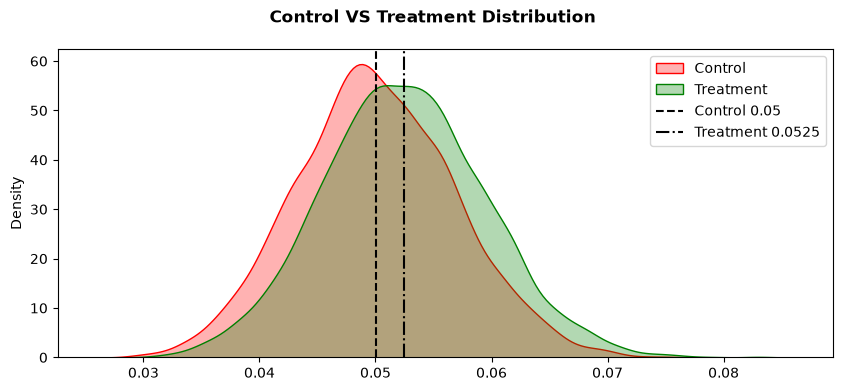

In [6]:
dump_size = 1000
simulation_trials = 10000
ctr_control_distribution, ctr_treatment_distribution = CLT_simulation(control=v_A, 
                                                                      treatment=v_B, 
                                                                      dump_size=dump_size,
                                                                      simulation_trials = simulation_trials)
control_mean = ctr_control_distribution.mean()
treatment_mean = ctr_treatment_distribution.mean()

print(f"Control Distribution Mean: {control_mean}")
print(f"Treatment Distribution Mean: {control_mean}")

_ = distribution_plot(ctr_control_distribution=ctr_control_distribution,
                      ctr_treatment_distribution = ctr_treatment_distribution,
                      control_mean=control_mean,
                      treatment_mean=treatment_mean)